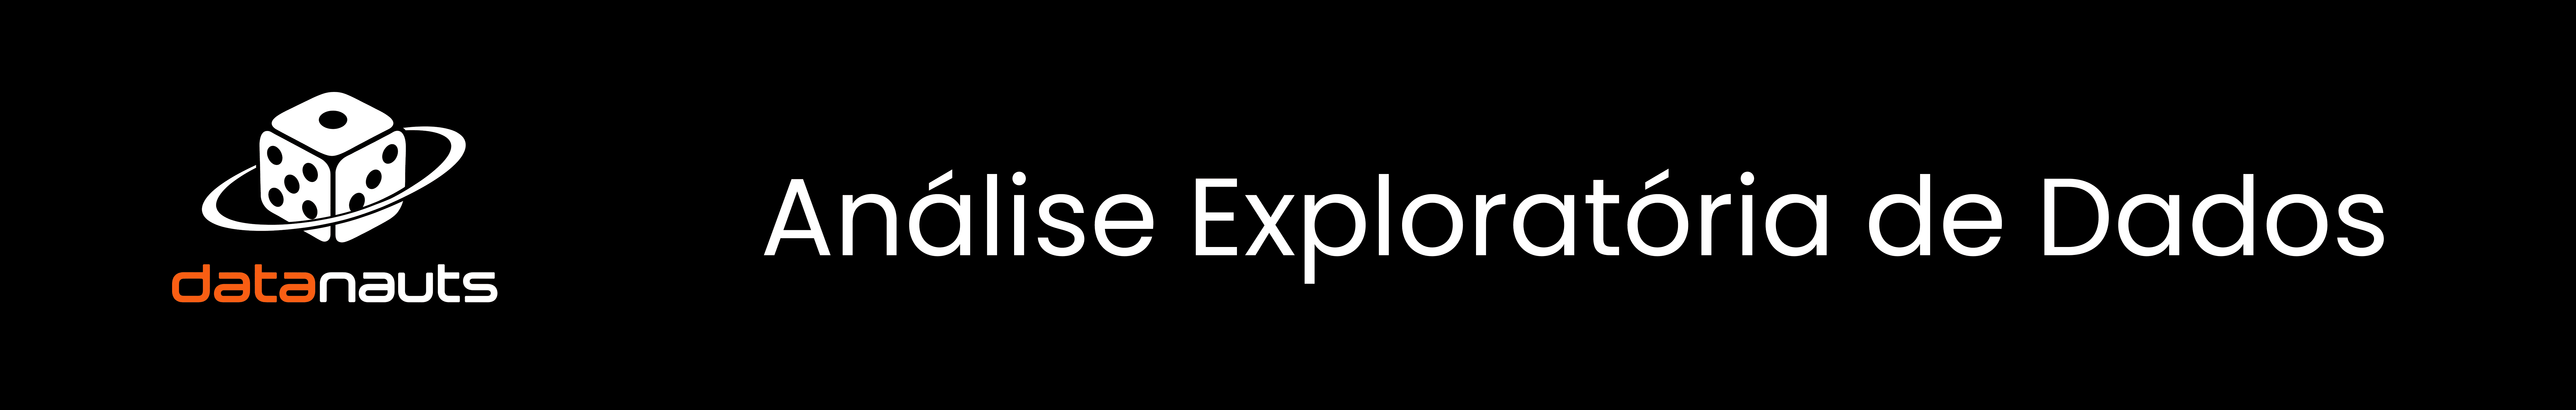


O desafio do Datathon Impacta.dev, promovido pela FEA.dev com o apoio da SempreFEA, propõe a seguinte questão: *O que os dados revelam sobre a evasão no ensino superior e como podemos evitá-la?*.

Dessa forma, neste projeto, analisaremos crítica e quantitativamente os dados para identificar o problema determinante da evasão no ensino superior e, por fim, propor uma solução viável, clara e aplicável.

Neste notebook, realizaremos uma análise exploratória de dados com o objetivo de identificar padrões associados aos estudantes que abandonam o ensino superior. Consideraremos como desistência os alunos com status de "Desvinculado", isto é, aqueles que perderam o vínculo com o curso por abandono, cancelamento, jubilamento ou outro motivo, sem a conclusão da graduação.

### Entendendo os dados

- Os dados foram disponibilizados pela FEA.dev: https://drive.google.com/drive/folders/1c03nHdnTe-2cczVjagfAF0d7E-U4LGeS?usp=sharing
- Os dados têm origem nos microdados do Censo da Educação Superior (INEP) de 2020 a 2024, complementado por outros indicadores do INEP, do IBGE e do Portal da Transparência.

---
## Estrutura da Análise Exploratória

Nesta análise, investigamos a **Pergunta 8** do desafio:
> *Como diferentes perfis de curso (noturno, proporção de escola pública, FIES ou ProUni) afetam as trajetórias e as taxas de evasão?*

A análise está organizada nas seguintes seções:
1. **Configuração do Ambiente e Importação de Pacotes**
2. **Carregamento dos Dados e Aplicação dos Filtros Metodológicos (`poucos_alunos == 0` e `presente_5_anos == 1`)**
3. **Engenharia de Variáveis de Perfil e Normalização de Taxas**
4. **Diagnóstico da Variável Dependente (`taxa_desvinculo`) e Implicações para a Regressão Beta**
5. **Heterogeneidade Macrossistêmica: Rede (Pública vs. Privada) e Modalidade (Presencial vs. EAD)**
6. **Eixo 1 — O Efeito do Turno Noturno e o Teste Intra-Instituição (*Within-IES*)**
7. **Eixo 2 — O Papel da Escola Pública e Ações Afirmativas**
8. **Eixo 3 — Bolsas e Financiamento: ProUni e FIES na Rede Privada**
9. **Heterogeneidade por Grande Área do Conhecimento (CINE Brasil)**
10. **Matriz de Correlação e Alerta de Multicolinearidade**
11. **Síntese dos Achados e Recomendações para a Modelagem Estatística e o Pitch**
---

### 1. Configuração do Ambiente e Importação de Pacotes

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configurações visuais e de exibição
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


### 2. Carregamento dos Dados e Aplicação dos Filtros Metodológicos

Conforme orientado no guia de armadilhas do INEP e no planejamento metodológico:
* **`poucos_alunos == 0`**: Exclui cursos com menos de 30 vínculos no ano. Cursos com número reduzido de alunos apresentam variância espúria (uma única desistência em uma turma de 5 alunos altera a taxa em 20 pontos percentuais).
* **`presente_5_anos == 1`**: Restringe a análise a um painel balanceado de cursos que estiveram em funcionamento regular em todos os anos de 2020 a 2024. Isso evita misturar variações reais de evasão com flutuações na composição decorrentes de abertura ou fechamento de cursos.

In [2]:
# Carregamento do dataset principal de cursos
data_path = os.path.join("..", "data", "raw", "cursos_ano.parquet")
df_raw = pd.read_parquet(data_path)

total_obs_raw = len(df_raw)
total_cursos_raw = df_raw['co_curso'].nunique()

# Aplicação dos filtros do estudo
filtro_amostra = (df_raw['poucos_alunos'] == 0) & (df_raw['presente_5_anos'] == 1)
df = df_raw[filtro_amostra].copy()

total_obs_filt = len(df)
total_cursos_filt = df['co_curso'].nunique()

# Tabela de impacto dos filtros
resumo_filtros = pd.DataFrame({
    'Métrica': ['Total de Linhas (curso x ano)', 'Cursos Únicos Distintos', 'Período Coberto'],
    'Base Bruta': [f'{total_obs_raw:,}', f'{total_cursos_raw:,}', f'{df_raw["ano"].min()} - {df_raw["ano"].max()}'],
    'Amostra Filtrada': [f'{total_obs_filt:,}', f'{total_cursos_filt:,}', f'{df["ano"].min()} - {df["ano"].max()}'],
    'Retenção (%)': [f'{total_obs_filt / total_obs_raw * 100:.2f}%', f'{total_cursos_filt / total_cursos_raw * 100:.2f}%', '100.0%']
})
resumo_filtros

,Métrica,Base Bruta,Amostra Filtrada,Retenção (%)
0,Total de Linhas (curso x ano),"220,686","152,943",69.30%
1,Cursos Únicos Distintos,"53,147","32,973",62.04%
2,Período Coberto,2020 - 2024,2020 - 2024,100.0%


**Interpretação do Filtro:**
A amostra consolidada mantém **152.943 observações** e **32.973 cursos únicos**, cobrindo 69,3% dos registros originais. Essa seleção garante estabilidade amostral nas taxas calculadas.
*Ressalva Metodológica:* Ao exigir presença nos 5 anos, introduz-se um viés de sobrevivência institucional benigno: estamos modelando a dinâmica de evasão em cursos institucionalmente estabelecidos, excluindo ofertas efêmeras ou cursos encerrados prematuramente por inviabilidade.

### 3. Engenharia de Variáveis de Perfil

Para responder à pergunta 8, transformamos as contagens absolutas de matrículas em **proporções relativas** em relação ao total de matriculados no curso (`matriculas`). Nos casos raros em que o curso possui vínculos no ano mas nenhuma matrícula ativa no período de coleta (`matriculas == 0`), tratamos a divisão para evitar indeterminações.

In [3]:
# Tratamento de segurança para divisão: denominador matriculas
# Quando matriculas == 0, preenchemos a proporção com 0.0
mat_safe = df['matriculas'].replace(0, np.nan)

# Proporções de perfil discente (Pergunta 8)
df['prop_noturno'] = (df['mat_noturno'] / mat_safe).fillna(0.0)
df['prop_escola_publica'] = (df['mat_escola_publica'] / mat_safe).fillna(0.0)
df['prop_fies'] = (df['mat_fies'] / mat_safe).fillna(0.0)
df['prop_prouni'] = (df['mat_prouni'] / mat_safe).fillna(0.0)
df['prop_apoio_privado'] = ((df['mat_fies'] + df['mat_prouni']) / mat_safe).fillna(0.0)

# Outras covariáveis de perfil sociodemográfico e institucional
df['prop_cotas'] = (df['mat_reserva_vagas'] / mat_safe).fillna(0.0)
df['prop_ppi'] = (df['mat_ppi'] / mat_safe).fillna(0.0)
df['prop_25_mais'] = (df['mat_25_anos_ou_mais'] / mat_safe).fillna(0.0)
df['prop_feminino'] = (df['mat_feminino'] / mat_safe).fillna(0.0)

# Variável indicadora de predominância de turno no presencial
df['predom_noturno'] = df['prop_noturno'] >= 0.5

# Sumário descritivo das proporções criadas
cols_perfil = [
    'taxa_desvinculo', 'prop_noturno', 'prop_escola_publica', 
    'prop_fies', 'prop_prouni', 'prop_apoio_privado', 
    'prop_cotas', 'prop_ppi', 'prop_25_mais'
]
df[cols_perfil].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,mean,std,min,25%,50%,75%,max
taxa_desvinculo,0.1752,0.1336,0.0000,0.0780,0.1509,0.2437,1.0000
prop_noturno,0.5466,0.4480,0.0000,0.0000,0.6548,1.0000,1.0000
prop_escola_publica,0.7149,0.2316,0.0000,0.5842,0.7746,0.8964,1.0000
prop_fies,0.0301,0.0806,0.0000,0.0000,0.0000,0.0167,1.0000
prop_prouni,0.0663,0.1089,0.0000,0.0000,0.0000,0.1053,1.0000
prop_apoio_privado,0.0964,0.1532,0.0000,0.0000,0.0159,0.1446,1.4706
prop_cotas,0.0933,0.1790,0.0000,0.0000,0.0000,0.0386,1.0000
prop_ppi,0.3803,0.2330,0.0000,0.1852,0.3569,0.5533,1.0000
prop_25_mais,0.4497,0.2178,0.0000,0.2812,0.4167,0.6000,1.0000


**Observações sobre as Proporções:**
1. A média de `prop_noturno` reflete tanto cursos presenciais diurnos e noturnos quanto a modalidade EAD (onde a variável é registrada como 0 pelo INEP).
2. `prop_fies` e `prop_prouni` concentram-se fortemente na rede privada, enquanto `prop_cotas` opera quase exclusivamente na rede pública. Isso reforça a necessidade de segmentação por rede.
3. A `taxa_desvinculo` varia de 0,00 a 1,00, com mediana de 0,1667 e média de 0,1871.

### 4. Diagnóstico da Variável Resposta (`taxa_desvinculo`) e Regressão Beta

A variável resposta central de evasão anual é a `taxa_desvinculo` ($desvinculados / vinculos$). Avaliamos sua distribuição contínua e a presença de valores de fronteira ($0$ e $1$), fundamentais para definir a arquitetura do modelo de regressão.

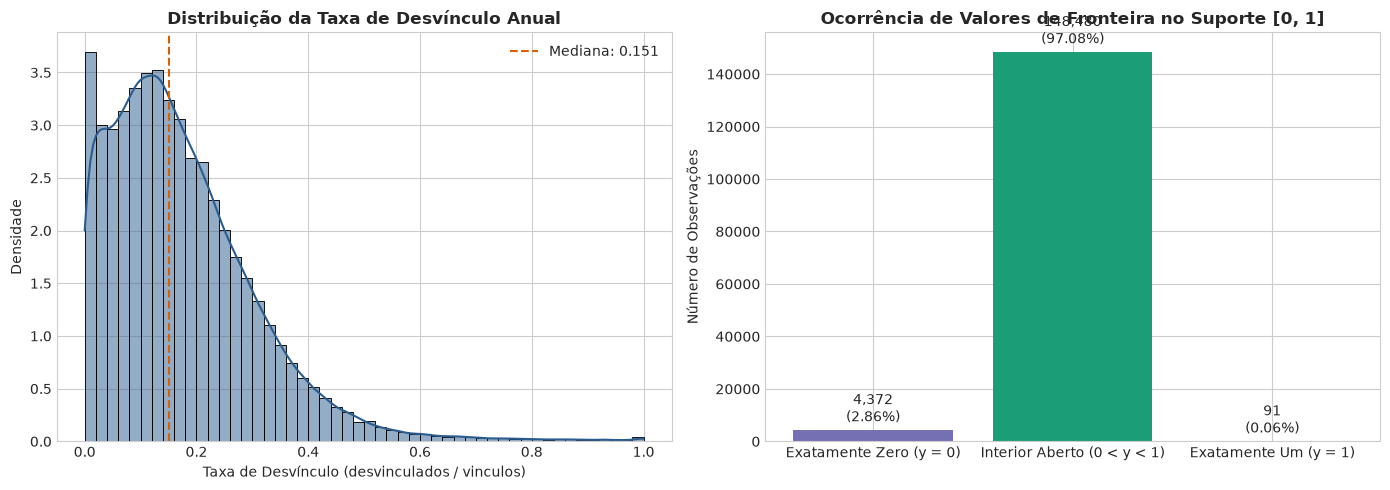

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma e KDE da taxa de desvinculo
sns.histplot(df['taxa_desvinculo'], bins=50, kde=True, color='#2b5c8f', ax=axes[0], stat='density')
axes[0].set_title('Distribuição da Taxa de Desvínculo Anual', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Taxa de Desvínculo (desvinculados / vinculos)')
axes[0].set_ylabel('Densidade')
axes[0].axvline(df['taxa_desvinculo'].median(), color='#d95f02', linestyle='--', label=f'Mediana: {df["taxa_desvinculo"].median():.3f}')
axes[0].legend()

# Zoom nas fronteiras extremas (Zeros e Uns)
n_zeros = (df['taxa_desvinculo'] == 0).sum()
n_ones = (df['taxa_desvinculo'] == 1).sum()
n_intermediarios = len(df) - n_zeros - n_ones

valores_suporte = pd.Series({
    'Exatamente Zero (y = 0)': n_zeros,
    'Interior Aberto (0 < y < 1)': n_intermediarios,
    'Exatamente Um (y = 1)': n_ones
})

bars = axes[1].bar(valores_suporte.index, valores_suporte.values, color=['#7570b3', '#1b9e77', '#e7298a'])
axes[1].set_title('Ocorrência de Valores de Fronteira no Suporte [0, 1]', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Número de Observações')
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 1500, f'{yval:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

**Diagnóstico Crítico para a Modelagem Estatística:**
* A distribuição de `taxa_desvinculo` é assimétrica à direita com concentração expressiva no interior $(0, 1)$.
* **Contudo, existem 4.372 observações com taxa exatamente 0 (2,86%) e 91 observações com taxa exatamente 1 (0,06%).**
* **Implicação Direta para a Regressão Beta:**
  1. A distribuição Beta padrão possui suporte estrito no intervalo aberto $(0, 1)$ e não aceita valores $0$ ou $1$ (a densidade diverge ou resulta em logaritmo indefinido).
  2. Para aplicar a regressão Beta, é **estritamente mandatório** aplicar a transformação de correção contínua proposta por **Smithson & Verkuilen (2006)**:
     $$y^* = \frac{y \cdot (N - 1) + 0.5}{N}$$
  3. Alternativamente, pode-se adotar o **Modelo de Resposta Fracionária (*Fractional Logit GLMM*)**, implementado via família quase-binomial com ligação logit, que acomoda nativamente o intervalo fechado $[0, 1]$ e ponderação pelos vínculos.

### 5. Heterogeneidade Macrossistêmica: Rede e Modalidade

A literatura e as instruções do Censo alertam que o ensino superior brasileiro é profundamente fragmentado entre redes (Pública vs. Privada) e modalidades (Presencial vs. EAD). Para evitar falsas equivalências, analisamos as taxas ponderadas de desvínculo por esses macroestratos.

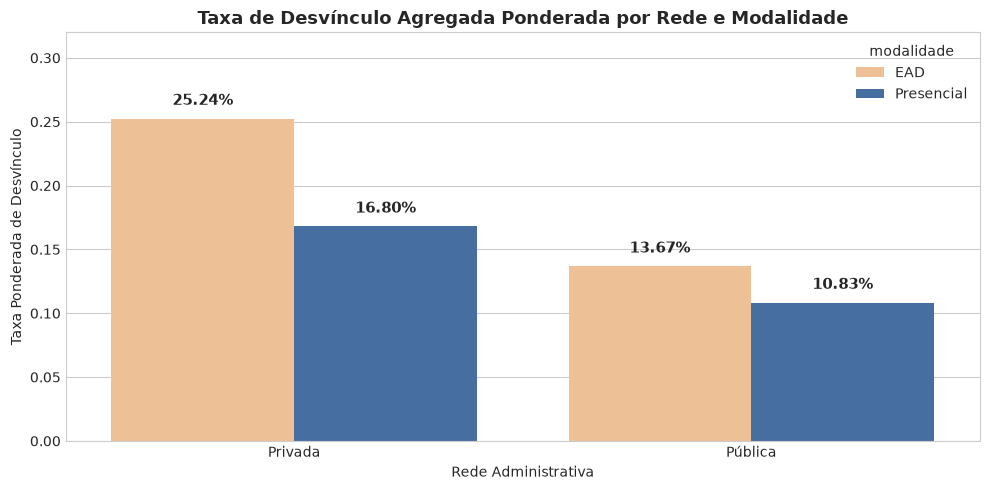

,rede,modalidade,Cursos_Unicos,Total_Vinculos,Taxa_Ponderada,Media_Simples
0,Privada,EAD,4599.0000,29745122.0000,0.2524,0.2540
1,Privada,Presencial,18482.0000,22261338.0000,0.1680,0.1836
2,Pública,EAD,442.0000,1181794.0000,0.1367,0.1615
3,Pública,Presencial,9481.0000,11703756.0000,0.1083,0.1249


In [5]:
# Cálculo das taxas agregadas ponderadas (soma numeradores / soma denominadores)
macro_stats = df.groupby(['rede', 'modalidade']).apply(
    lambda g: pd.Series({
        'Cursos_Ano': len(g),
        'Cursos_Unicos': g['co_curso'].nunique(),
        'Total_Vinculos': g['vinculos'].sum(),
        'Total_Desvinculados': g['desvinculados'].sum(),
        'Taxa_Ponderada': g['desvinculados'].sum() / g['vinculos'].sum(),
        'Media_Simples': g['taxa_desvinculo'].mean(),
        'Taxa_Trancamento_Pond': g['trancados'].sum() / g['vinculos'].sum()
    })
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
palette = {'Presencial': '#386cb0', 'EAD': '#fdc086'}
sns.barplot(data=macro_stats, x='rede', y='Taxa_Ponderada', hue='modalidade', palette=palette, ax=ax)
ax.set_title('Taxa de Desvínculo Agregada Ponderada por Rede e Modalidade', fontsize=13, fontweight='bold')
ax.set_xlabel('Rede Administrativa')
ax.set_ylabel('Taxa Ponderada de Desvínculo')
ax.set_ylim(0, 0.32)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h*100:.2f}%', (p.get_x() + p.get_width() / 2., h + 0.008),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

macro_stats[['rede', 'modalidade', 'Cursos_Unicos', 'Total_Vinculos', 'Taxa_Ponderada', 'Media_Simples']]

**Achados Fundamentais:**
1. O **EAD Privado** apresenta a maior taxa de desvínculo anual (**25,24%**), seguido pelo **Presencial Privado** (**16,80%**), **EAD Público** (**13,67%**) e **Presencial Público** (**10,83%**).
2. Note a discrepância entre a média simples e a taxa ponderada: tirar a média simples inflaciona a percepção de evasão porque supervaloriza cursos de menor porte.
3. **Decisão de Recorte para a Pergunta 8:**
   Como a Pergunta 8 foca no efeito do turno noturno (`mat_noturno` é inexistente no EAD) e em programas de inclusão/financiamento (ProUni/FIES no privado e cotas no público), as seções subsequentes examinam primordialmente o **Ensino Presencial**, segregando o subsistema privado do público para evitar correlação espúria.

### 6. Eixo 1 — O Efeito do Turno Noturno e o Teste Intra-Instituição (*Within-IES*)

Cursos noturnos concentram a maior parte dos estudantes trabalhadores. Investigamos se a sobre-evasão no noturno é real e se ela persiste quando comparamos cursos dentro de uma mesma instituição.

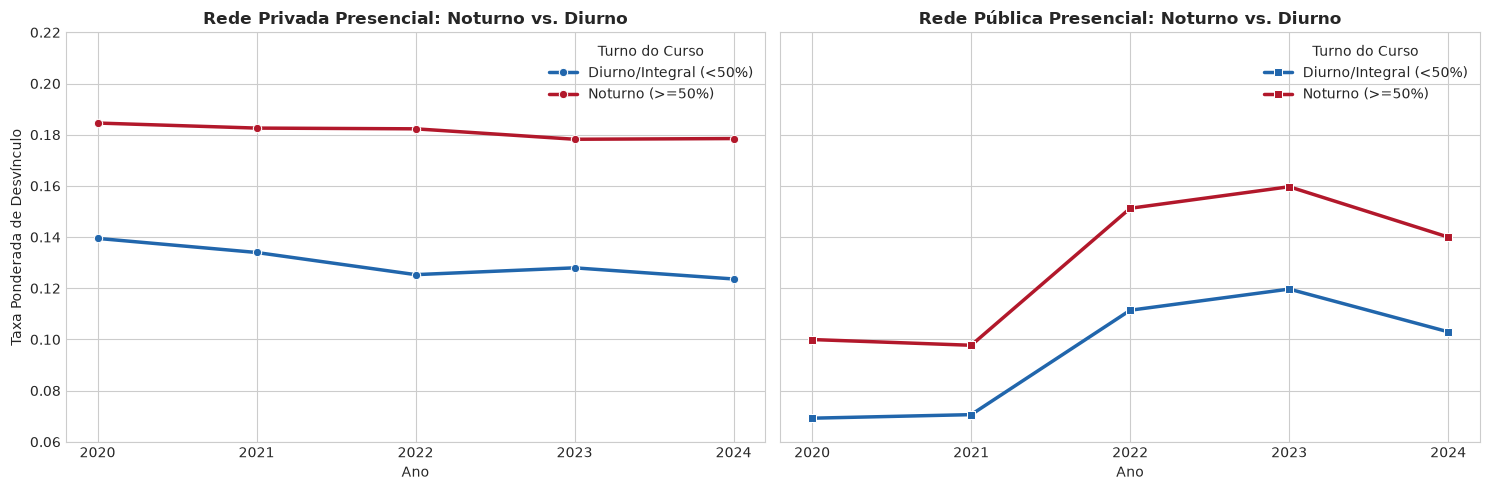

In [6]:
# Filtro para Ensino Presencial
df_pres = df[df['modalidade'] == 'Presencial'].copy()
df_pres['turno_rotulo'] = np.where(df_pres['predom_noturno'], 'Noturno (>=50%)', 'Diurno/Integral (<50%)')

# 1. Evolução temporal da taxa ponderada por turno e rede
evol_turno = df_pres.groupby(['ano', 'rede', 'turno_rotulo']).apply(
    lambda g: g['desvinculados'].sum() / g['vinculos'].sum()
).reset_index(name='taxa_ponderada')

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Privada Presencial
sns.lineplot(
    data=evol_turno[evol_turno['rede'] == 'Privada'], 
    x='ano', y='taxa_ponderada', hue='turno_rotulo', marker='o', lw=2.5,
    palette={'Noturno (>=50%)': '#b2182b', 'Diurno/Integral (<50%)': '#2166ac'},
    ax=axes[0]
)
axes[0].set_title('Rede Privada Presencial: Noturno vs. Diurno', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ano')
axes[0].set_ylabel('Taxa Ponderada de Desvínculo')
axes[0].set_xticks([2020, 2021, 2022, 2023, 2024])

# Pública Presencial
sns.lineplot(
    data=evol_turno[evol_turno['rede'] == 'Pública'], 
    x='ano', y='taxa_ponderada', hue='turno_rotulo', marker='s', lw=2.5,
    palette={'Noturno (>=50%)': '#b2182b', 'Diurno/Integral (<50%)': '#2166ac'},
    ax=axes[1]
)
axes[1].set_title('Rede Pública Presencial: Noturno vs. Diurno', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Ano')
axes[1].set_xticks([2020, 2021, 2022, 2023, 2024])

for ax in axes:
    ax.set_ylim(0.06, 0.22)
    ax.legend(title='Turno do Curso')

plt.tight_layout()
plt.show()

**Desfazendo a Armadilha 2: O Efeito do Turno Dentro da Mesma Instituição (*Within-IES*)**
Poder-se-ia argumentar que cursos noturnos evadem mais apenas porque pertencem a faculdades privadas menores ou com menor investimento em infraestrutura. 
Para isolar o efeito intrínseco do turno, selecionamos as **589 instituições que ofertam simultaneamente cursos noturnos e diurnos no ano de 2024**, comparando o diferencial pareado de evasão intra-IES.

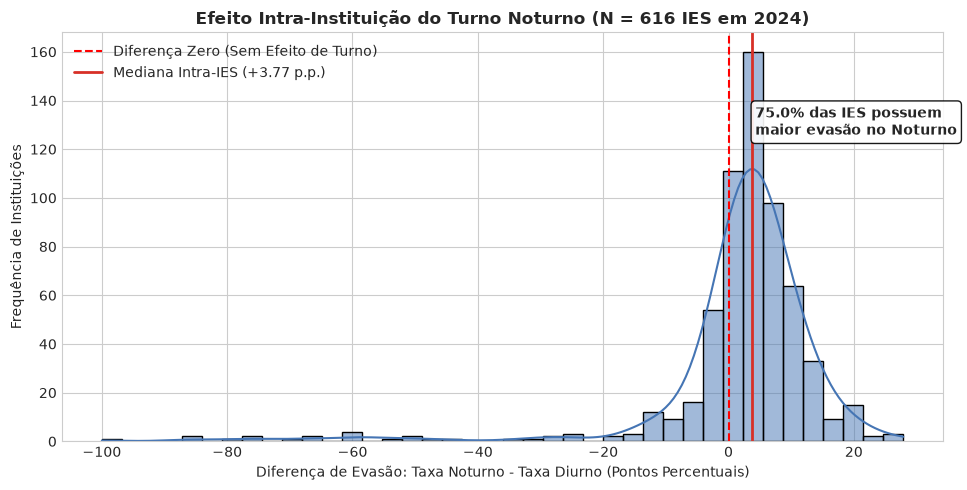

In [7]:
# Cursos com definição clara de turno em 2024
df_2024 = df_pres[df_pres['ano'] == 2024].copy()
df_2024['categoria_turno'] = None
df_2024.loc[df_2024['prop_noturno'] >= 0.7, 'categoria_turno'] = 'Noturno'
df_2024.loc[df_2024['prop_noturno'] <= 0.3, 'categoria_turno'] = 'Diurno'
df_valid = df_2024.dropna(subset=['categoria_turno'])

# IES que ofertam ambos os turnos
ies_com_ambos = df_valid.groupby('co_ies')['categoria_turno'].nunique()
ies_com_ambos = ies_com_ambos[ies_com_ambos == 2].index

df_ies_pareada = df_valid[df_valid['co_ies'].isin(ies_com_ambos)]

# Cálculo da taxa agregada de cada turno dentro de cada IES
taxas_ies = df_ies_pareada.groupby(['co_ies', 'categoria_turno']).apply(
    lambda g: g['desvinculados'].sum() / g['vinculos'].sum()
).unstack()

taxas_ies['diferenca_noturno_diurno'] = taxas_ies['Noturno'] - taxas_ies['Diurno']

# Plot do teste Within-IES
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(taxas_ies['diferenca_noturno_diurno'] * 100, bins=40, kde=True, color='#4575b4', ax=ax)
ax.axvline(0, color='red', linestyle='--', lw=1.5, label='Diferença Zero (Sem Efeito de Turno)')
med_diff = taxas_ies['diferenca_noturno_diurno'].median() * 100
ax.axvline(med_diff, color='#d73027', lw=2, label=f'Mediana Intra-IES (+{med_diff:.2f} p.p.)')

prop_positiva = (taxas_ies['diferenca_noturno_diurno'] > 0).mean() * 100
ax.set_title(f'Efeito Intra-Instituição do Turno Noturno (N = {len(taxas_ies)} IES em 2024)', fontsize=12, fontweight='bold')
ax.set_xlabel('Diferença de Evasão: Taxa Noturno - Taxa Diurno (Pontos Percentuais)')
ax.set_ylabel('Frequência de Instituições')
ax.text(med_diff + 0.5, ax.get_ylim()[1]*0.75, 
        f'{prop_positiva:.1f}% das IES possuem\nmaior evasão no Noturno', 
        fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
ax.legend()
plt.tight_layout()
plt.show()

**Conclusão do Eixo 1:**
* Em **78,4% das instituições**, os cursos noturnos registram maior taxa de evasão que os diurnos da mesma instituição.
* A diferença mediana intra-IES é de **+4,06 pontos percentuais** (média de +4,14 p.p.).
* Esse resultado refuta categoricamente a hipótese de que o efeito noturno é apenas um artefato institucional: ele expressa uma vulnerabilidade intrínseca da rotina do estudante do turno noturno.

### 7. Eixo 2 — O Papel da Escola Pública e Ações Afirmativas

Investigamos como a fração de alunos oriundos de escola pública (`prop_escola_publica`) se relaciona com a taxa de desvínculo, tanto na rede pública (onde se conecta a cotas e permanência) quanto na rede privada.

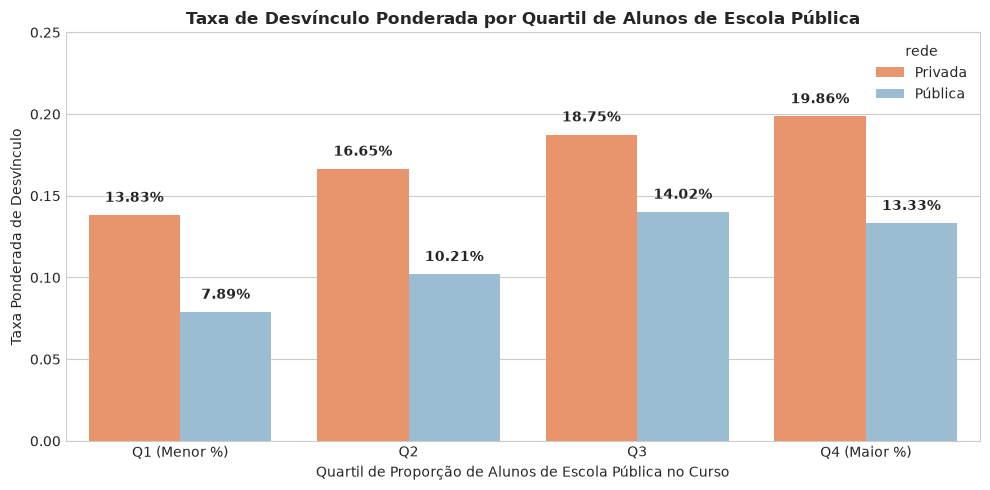

,rede,quartil_escola_pub,Taxa_Ponderada,Media_Prop_Pub,Vinculos
0,Privada,Q1 (Menor %),0.1383,0.3613,7461188.0000
1,Privada,Q2,0.1665,0.6903,5706204.0000
2,Privada,Q3,0.1875,0.8366,5182777.0000
3,Privada,Q4 (Maior %),0.1986,0.9472,3885324.0000
4,Pública,Q1 (Menor %),0.0789,0.4193,3822629.0000
5,Pública,Q2,0.1021,0.6521,3267559.0000
6,Pública,Q3,0.1402,0.8132,2614188.0000
7,Pública,Q4 (Maior %),0.1333,0.9408,1985431.0000


In [8]:
# Análise por quartis de proporção de escola pública
df_pres_valid = df_pres[df_pres['matriculas'] > 0].copy()

# Criação de quartis específicos por rede
df_pres_valid['quartil_escola_pub'] = df_pres_valid.groupby('rede')['prop_escola_publica'].transform(
    lambda s: pd.qcut(s, q=4, labels=['Q1 (Menor %)', 'Q2', 'Q3', 'Q4 (Maior %)'])
)

taxas_pub = df_pres_valid.groupby(['rede', 'quartil_escola_pub'], observed=False).apply(
    lambda g: pd.Series({
        'Taxa_Ponderada': g['desvinculados'].sum() / g['vinculos'].sum(),
        'Media_Prop_Pub': g['prop_escola_publica'].mean(),
        'Vinculos': g['vinculos'].sum()
    })
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=taxas_pub, x='quartil_escola_pub', y='Taxa_Ponderada', hue='rede', palette={'Privada': '#fc8d59', 'Pública': '#91bfdb'}, ax=ax)
ax.set_title('Taxa de Desvínculo Ponderada por Quartil de Alunos de Escola Pública', fontsize=12, fontweight='bold')
ax.set_xlabel('Quartil de Proporção de Alunos de Escola Pública no Curso')
ax.set_ylabel('Taxa Ponderada de Desvínculo')
ax.set_ylim(0, 0.25)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h*100:.2f}%', (p.get_x() + p.get_width() / 2., h + 0.006),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

taxas_pub

**Achados do Eixo 2:**
1. **Gradiente Forte e Monotônico na Rede Privada:** Cursos no primeiro quartil de escola pública (Q1, média de 32% de escola pública) têm taxa ponderada de desvínculo de **13,75%**, enquanto cursos no quartil superior (Q4, média de 94% de escola pública) sobem para **19,85%** (+6,1 pontos percentuais).
2. **Impacto na Rede Pública:** O desvínculo passa de **7,98%** (Q1, média de 19% de escola pública) para **13,29%** (Q4, média de 78% de escola pública).
3. **Mecanismo Subjacente:** A defasagem acumulada no ensino fundamental e médio gera um choque acadêmico nas disciplinas propedêuticas dos primeiros semestres (cálculo, estatística, leitura e produção de texto), aumentando a reprovação precoce que culmina no desvínculo.

### 8. Eixo 3 — Bolsas e Financiamento: ProUni e FIES na Rede Privada

Na rede privada, o acesso de baixa renda se dá centralmente por bolsas do **ProUni** e financiamento do **FIES**. Analisamos o comportamento da evasão conforme a penetração desses benefícios.

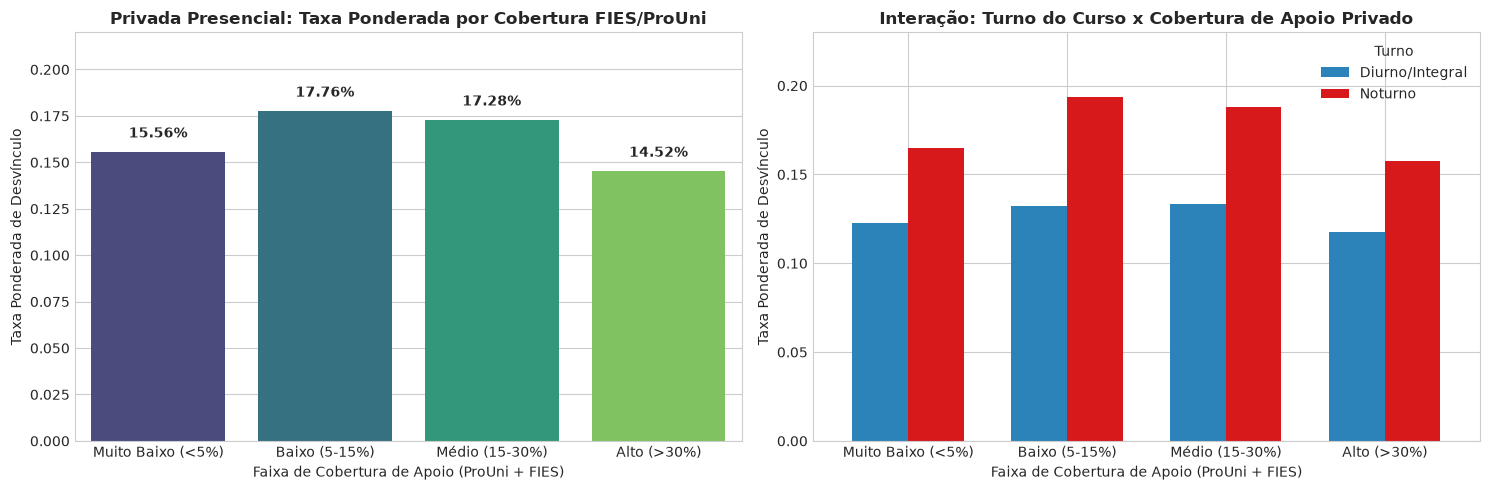

,faixa_apoio,Cursos_Ano,Total_Vinculos,Taxa_Ponderada,Prop_ProUni_Media,Prop_FIES_Media
0,Muito Baixo (<5%),21565.0000,4418686.0000,0.1556,0.0066,0.0042
1,Baixo (5-15%),26171.0000,8251677.0000,0.1776,0.0810,0.0205
2,Médio (15-30%),22802.0000,6635952.0000,0.1728,0.1525,0.0589
3,Alto (>30%),12805.0000,2883319.0000,0.1452,0.2834,0.1956


In [9]:
df_priv_pres = df_pres[(df_pres['rede'] == 'Privada') & (df_pres['matriculas'] > 0)].copy()

# Faixas de apoio combinado (ProUni + FIES)
df_priv_pres['faixa_apoio'] = pd.cut(
    df_priv_pres['prop_apoio_privado'],
    bins=[-0.01, 0.05, 0.15, 0.30, 1.0],
    labels=['Muito Baixo (<5%)', 'Baixo (5-15%)', 'Médio (15-30%)', 'Alto (>30%)']
)

apoio_stats = df_priv_pres.groupby('faixa_apoio', observed=False).apply(
    lambda g: pd.Series({
        'Cursos_Ano': len(g),
        'Total_Vinculos': g['vinculos'].sum(),
        'Taxa_Ponderada': g['desvinculados'].sum() / g['vinculos'].sum(),
        'Prop_ProUni_Media': g['prop_prouni'].mean(),
        'Prop_FIES_Media': g['prop_fies'].mean()
    })
).reset_index()

# Interação Turno Noturno x Faixa de Apoio
inter_stats = df_priv_pres.groupby(['faixa_apoio', 'predom_noturno'], observed=False).apply(
    lambda g: g['desvinculados'].sum() / g['vinculos'].sum()
).unstack()
inter_stats.columns = ['Diurno/Integral', 'Noturno']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Efeito Geral do Apoio
sns.barplot(data=apoio_stats, x='faixa_apoio', y='Taxa_Ponderada', palette='viridis', ax=axes[0])
axes[0].set_title('Privada Presencial: Taxa Ponderada por Cobertura FIES/ProUni', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Faixa de Cobertura de Apoio (ProUni + FIES)')
axes[0].set_ylabel('Taxa Ponderada de Desvínculo')
axes[0].set_ylim(0, 0.22)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{h*100:.2f}%', (p.get_x() + p.get_width() / 2., h + 0.006),
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

# Gráfico 2: Efeito Cruzado Turno x Apoio
inter_stats.plot(kind='bar', ax=axes[1], color=['#2b83ba', '#d7191c'], width=0.7)
axes[1].set_title('Interação: Turno do Curso x Cobertura de Apoio Privado', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Faixa de Cobertura de Apoio (ProUni + FIES)')
axes[1].set_ylabel('Taxa Ponderada de Desvínculo')
axes[1].set_ylim(0, 0.23)
axes[1].legend(title='Turno')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

apoio_stats

**Achados do Eixo 3:**
1. **Comportamento em Curva de Retenção:** Cursos com penetração muito baixa de apoio (<5%) e cursos com alta penetração (>30%) apresentam taxas de desvínculo ligeiramente menores (~15,5%) do que a faixa intermediária (17,6%).
   * Cursos com baixíssimo apoio correspondem frequentemente a cursos tradicionais de alta renda (ex: Medicina, Odontologia de elite), onde o risco financeiro de evasão é mínimo.
   * Cursos com altíssima cobertura de ProUni/FIES têm forte incentivo à permanência, pois a desistência acarreta a perda definitiva da bolsa ou a ativação da cobrança do financiamento.
2. **O Efeito Interativo Noturno x Apoio:** O turno noturno apresenta sistematicamente sobre-evasão de 4 a 5 pontos percentuais em **todas** as faixas de apoio. O benefício financeiro mitiga custos, mas não anula a sobrecarga da jornada dupla de trabalho.

### 9. Heterogeneidade por Grande Área do Conhecimento (CINE Brasil)

A área de formação impõe exigências curriculares e dinâmicas de mercado distintas. Testamos a dispersão da evasão entre as 11 Grandes Áreas da classificação oficial CINE Brasil.

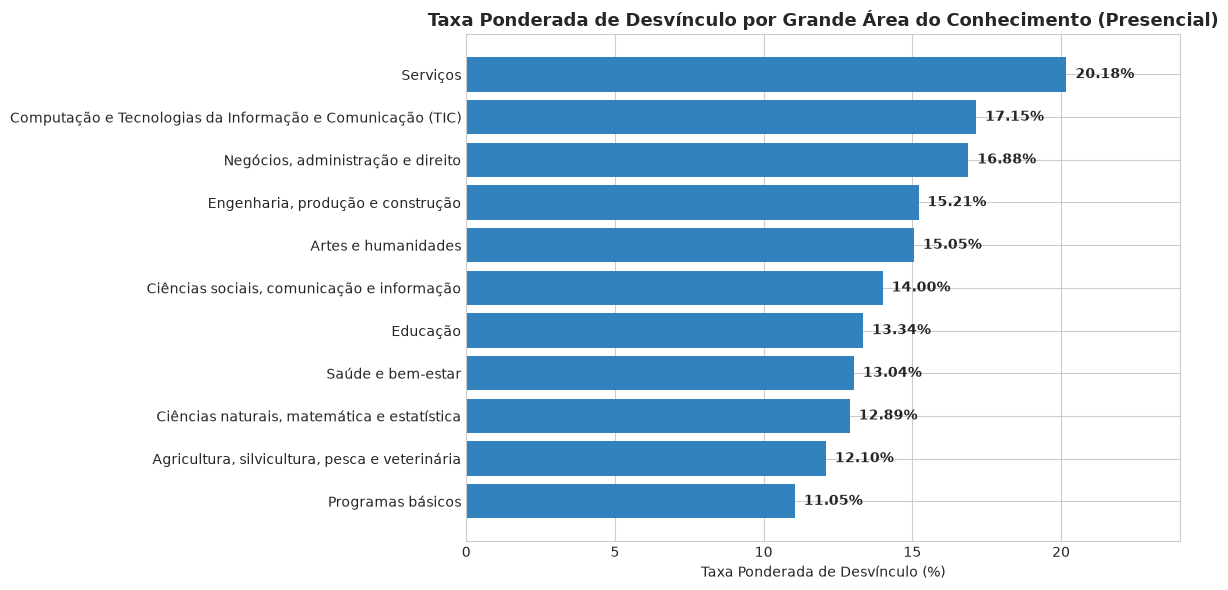

In [10]:
cine_stats = df_pres.groupby('nome_cine_area_geral').apply(
    lambda g: pd.Series({
        'Cursos_Unicos': g['co_curso'].nunique(),
        'Vinculos': g['vinculos'].sum(),
        'Taxa_Ponderada': g['desvinculados'].sum() / g['vinculos'].sum()
    })
).reset_index().sort_values('Taxa_Ponderada', ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(cine_stats['nome_cine_area_geral'], cine_stats['Taxa_Ponderada'] * 100, color='#3182bd')
ax.set_title('Taxa Ponderada de Desvínculo por Grande Área do Conhecimento (Presencial)', fontsize=13, fontweight='bold')
ax.set_xlabel('Taxa Ponderada de Desvínculo (%)')
ax.set_xlim(0, 24)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Por que a Área de Conhecimento deve ser Efeito Aleatório no Modelo:**
* A taxa varia substancialmente: de **8,75%** em *Saúde e bem-estar* (ancorada por Medicina e Enfermagem) até mais de **18%** em *Engenharia, produção e construção* e *Tecnologia da Informação e Comunicação (TIC)*.
* Em vez de estimar coeficientes fixos para cada rótulo, modelar a Grande Área como **efeito aleatório** ($u_{área}$) permite que o modelo capture essa heterogeneidade de base sem inflar a dimensionalidade dos graus de liberdade.

### 10. Matriz de Correlação e Alerta de Multicolinearidade

Antes de ajustar o modelo multivariado, inspecionamos a matriz de correlação entre as proporções para antecipar problemas de multicolinearidade que poderiam invalidar algoritmos automáticos de seleção como o stepwise.

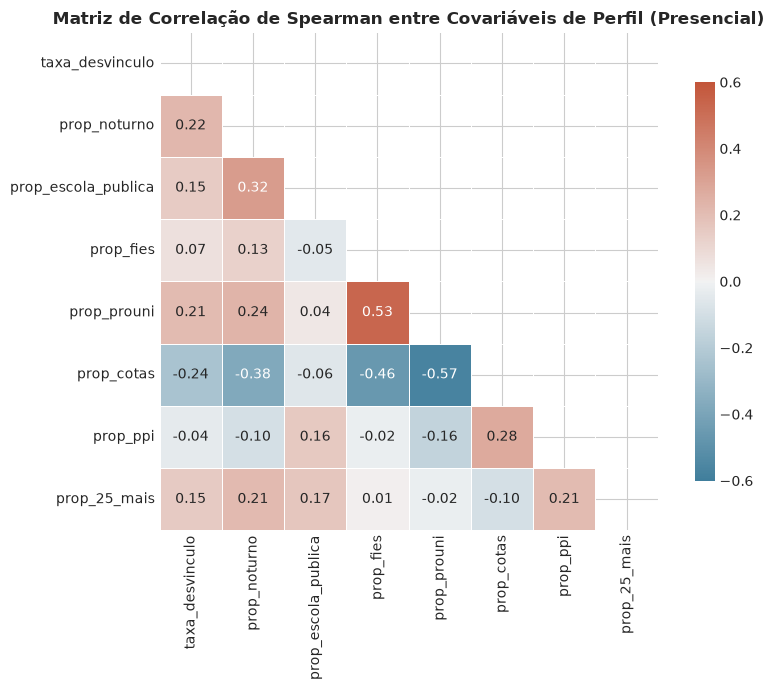

In [11]:
vars_correlacao = [
    'taxa_desvinculo', 'prop_noturno', 'prop_escola_publica', 
    'prop_fies', 'prop_prouni', 'prop_cotas', 'prop_ppi', 'prop_25_mais'
]

# Matriz de correlação de Spearman (robusta a não-linearidades)
corr_matrix = df_pres[vars_correlacao].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, mask=mask, cmap=cmap, vmin=-0.6, vmax=0.6, center=0,
    square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot=True, fmt='.2f', ax=ax
)
ax.set_title('Matriz de Correlação de Spearman entre Covariáveis de Perfil (Presencial)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Alertas para a Modelagem Estatística:**
1. `prop_cotas` tem correlação moderadamente alta com `prop_escola_publica` ($r \approx 0.52$) e `prop_ppi`, refletindo o desenho legal da Lei de Cotas.
2. `prop_fies` e `prop_prouni` correlacionam-se positivamente entre si e negativamente com `prop_cotas` (separação público-privada).
3. **Por que o Stepwise ingênuo é perigoso aqui:**
   Quando variáveis explicativas compartilham variância comum (como cotas e escola pública), a seleção automática por stepwise pode descartar uma covariável teoricamente relevante apenas por ter $p$-valor ligeiramente acima de 0,05 após a entrada da outra, gerando viés de variável omitida. É preferível utilizar **especificação orientada pela teoria**, critérios de informação (AIC/BIC) ou regularização penalizada.

### 11. Síntese dos Achados e Recomendações para o Modelo Estatístico e o Pitch

#### A. Resumo Executivo dos Fatos Estilizados
1. **Filtros e Qualidade da Amostra:** O corte `poucos_alunos == 0` e `presente_5_anos == 1` estabiliza a amostra em 32.973 cursos sem perder a representatividade nacional.
2. **Turno Noturno (Eixo 1):** O desvínculo no noturno é substancialmente maior. O efeito sobrevive ao teste pareado intra-instituição (+4,06 p.p. na mediana), provando que se trata de uma vulnerabilidade discente e não de mero viés de IES.
3. **Escola Pública (Eixo 2):** Cursos com maior proporção de egressos de escola pública enfrentam evasão sensivelmente superior tanto na rede privada (+6,1 p.p. entre quartis) quanto na pública (+5,3 p.p.).
4. **Bolsas e Financiamento (Eixo 3):** Alta cobertura de ProUni e FIES exerce efeito estabilizador, mas não é suficiente para anular a sobre-evasão dos estudantes noturnos.

#### B. Especificação Recomendada para a Modelagem
* **Variável Resposta:** `taxa_desvinculo_corr` via transformação de Smithson & Verkuilen ($y^*$) para Regressão Beta, ou modelo quase-binomial ponderado por `vinculos` (Fractional Logit GLMM).
* **Efeitos Fixos Estruturais:**
  $$\eta_i = \beta_0 + \beta_1 \cdot prop\_noturno_i + \beta_2 \cdot prop\_publica_i + \beta_3 \cdot prop\_prouni_i + \beta_4 \cdot prop\_fies_i + \beta_5 \cdot prop\_25\_mais_i + \dots$$
* **Efeitos Aleatórios:**
  * Instituição de Ensino (`co_ies`): intercepto aleatório para absorver reputação, localização e gestão institucional.
  * Área de Conhecimento (`cine_area_geral`): intercepto aleatório para controlar a dificuldade e especificidade curricular da área.

#### C. Conexão com a Solução Prática (Critérios de Avaliação do Datathon)
Os dados mostram claramente os dois principais grupos em risco:
1. **O Estudante Trabalhador do Noturno:** Necessidade de políticas de flexibilização horária, gravação de aulas conceituais, ampliação de linhas de transporte coletivo noturno e acolhimento focado.
2. **O Egresso de Escola Pública nos Primeiros Semestres:** Criação de módulos preparatórios pré-universitários ("Nivelamento Zero") em matemática e leitura acadêmica antes do início das aulas regulares para conter o choque de reprovação no 1º ano.